# 01 Trends: growth before and after 2019

The logic lives in `pipeline/tract/growth.py`. This notebook loads, calls and shows.

**What "before" and "after" mean**
- ACS 5-year estimates describe a window, not a year. Windows: 2010-14, 2015-19, 2020-24. Midpoints: 2012, 2017, 2022
- Before = 2010-14 to 2015-19 (about 2012 to 2017). After = 2015-19 to 2020-24 (about 2017 to 2022)
- So the ACS "after" step starts two years before 2019. Read it as "the most recent 5 years", not "since 2019"
- Jobs (LODES) are yearly counts: before = 2010 to 2019, after = 2019 to 2024
- Yearly rate = (end / start) ^ (1 / 5) - 1 for ACS, over 9 or 5 years for jobs

**Inputs**: `acs_tract.csv`, `acs_moe_tract.csv` (margins, from `python -m pipeline.tract.acs_moe`), `jobs_tract.csv`, `decennial_units_tract.csv`, `tracts_2020.gpkg`, the 2010 to 2020 block crosswalk

**Outputs**: `trends_tract.csv` (the tool reads it), `tract_panel.csv`, `processed/5500/growth_summary.json`

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 3)
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 60   # keeps the notebook small. Saved figures use 120 dpi

from pipeline.tract import growth, plots

In [2]:
r = growth.run()
print(len(r['trends']), 'tracts')

3445 tracts


## Statewide growth

- From summed tract counts, % per year. Rent is the median tract, in 2024 dollars

In [3]:
(r['statewide'] * 100).round(2)

,before,after,change
pop,0.05,0.35,0.30
units,0.41,0.39,-0.01
jobs,0.95,0.31,-0.64
"rent (median tract, real)",0.76,0.41,-0.35


In [4]:
r['sped'].round(3)

,share_sped_up,tracts_with_data
pop,0.543,3407.0
units,0.480,3385.0
jobs,0.420,3370.0
rent,0.435,3214.0


## Inflation

- ACS dollars are in the last year of each window. CPI-U (`tract.growth.cpi_u` in `shared/assumptions.json`) moves them to 2024 dollars
- Nominal median rent rose a lot. Real rent rose a little

In [5]:
r['inflation'].pivot(index='measure', columns='window', values=['nominal', 'dollars_2024']).round(0)

nominal                     dollars_2024                    
window          2010-14   2015-19   2020-24      2010-14   2015-19   2020-24
measure                                                                     
median_income   52083.0   60016.0   74844.0      69013.0   73639.0   74844.0
median_rent       820.0     917.0    1149.0       1087.0    1125.0    1149.0
median_value   153000.0  163400.0  230200.0     202734.0  200490.0  230200.0

## Margins of error

- ACS margins are at 90%. The margin of a difference between two windows is sqrt(m1^2 + m2^2)
- A change smaller than its margin is flagged in `trends_tract.csv` (`*_within_moe`)
- "change" = the change in the 5-year change (2020-24 minus twice 2015-19 plus 2010-14)

In [6]:
r['moe'].round(3)

,measure,part,tracts,share_within_moe
0,pop,before,3445,0.720
1,pop,after,3445,0.686
2,pop,change,3407,0.714
3,units,before,3445,0.785
4,units,after,3445,0.716
5,units,change,3385,0.754
6,rent,before,3294,0.809
7,rent,after,3218,0.801
8,rent,change,3180,0.849


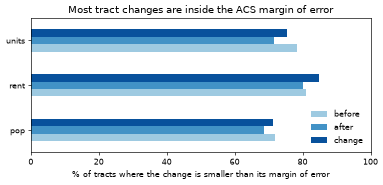

In [7]:
plots.moe_bars(r['moe']);

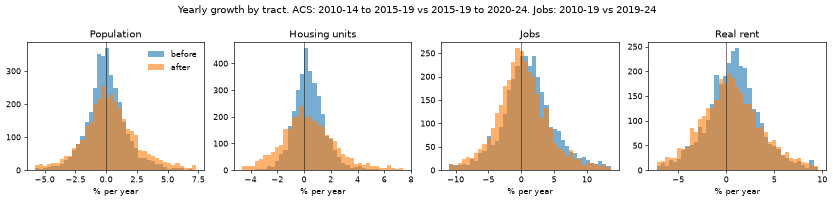

In [8]:
plots.growth_hist(r['trends']);

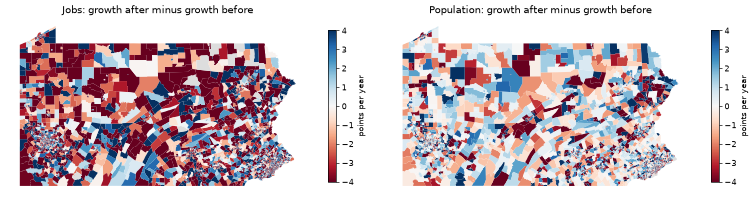

In [9]:
plots.trend_change_map(r['trends']);